# Unsupervised Learning: Clustering

In this exercise, you will explore the strengths and limitations of two popular clustering algorithms: **K-Means** and **DBSCAN**. You will apply both methods to a real-world dataset, the **Mall Customers dataset**, which presents challenges for traditional clustering approaches, particularly K-Means. 

The goal is to understand how DBSCAN can overcome some of these limitations and to evaluate the performance of each algorithm using various clustering evaluation metrics.



# 1. Dataset Exploration

We will use the **Mall Customers dataset**, which contains information about customers of a mall, including features such as age, annual income, and spending score. The dataset is useful for customer segmentation tasks, where the goal is to group customers into distinct clusters based on their behavior and demographics.


In [62]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Load the dataset
df = pd.read_csv('Mall_Customers.csv')

# Display the first few rows
print(df.head())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


## 1.1 Exploratory Data Analysis (EDA)

Before applying clustering algorithms, it's important to understand the structure and distribution of the dataset. In this section, we will perform exploratory data analysis to gain insights into the Mall Customers dataset, including examining the relationships between features and understanding the shape of the data in multiple dimensions.


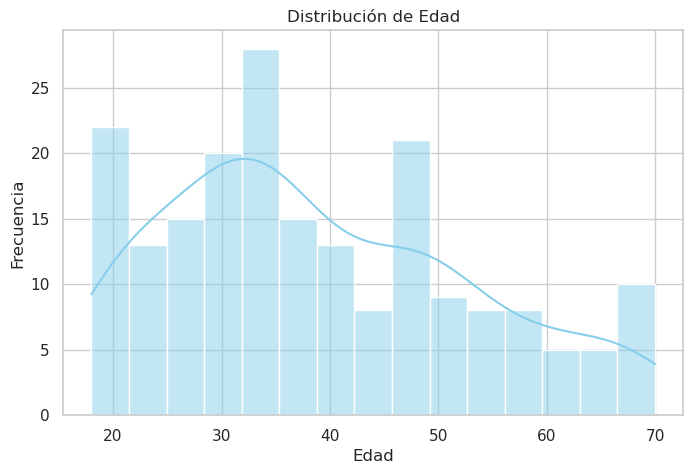

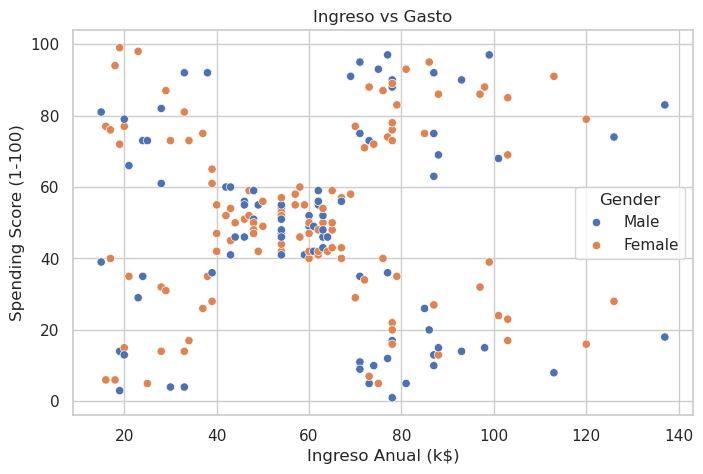

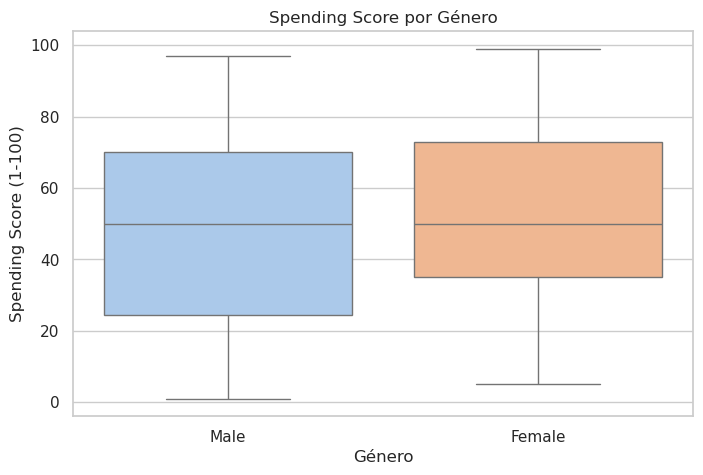

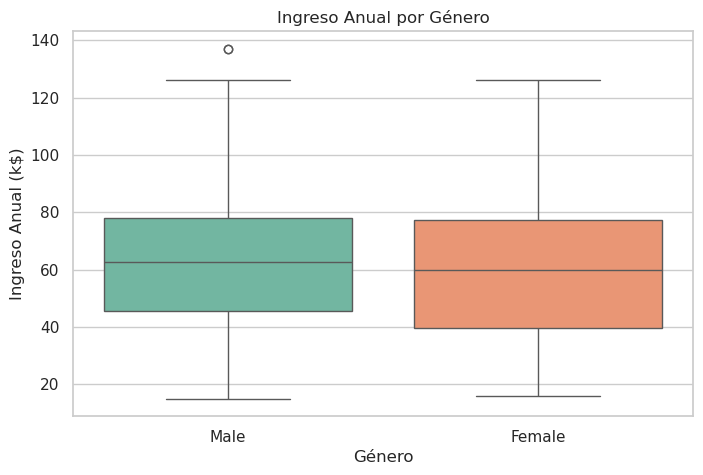

In [63]:
# Display basic statistics about the dataset using describe()

# Configuración estética
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)


# Distribución de Edad

sns.histplot(df['Age'], bins=15, kde=True, color='skyblue')
plt.title('Distribución de Edad')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()


# Ingreso vs Spending Score (Scatterplot)

sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)', data=df, hue='Gender')
plt.title('Ingreso vs Gasto')
plt.xlabel('Ingreso Anual (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

# Boxplot de Spending Score por Género

sns.boxplot(x='Gender', y='Spending Score (1-100)', data=df, hue='Gender', palette='pastel', legend=False)
plt.title('Spending Score por Género')
plt.xlabel('Género')
plt.ylabel('Spending Score (1-100)')
plt.show()


# Ingreso Anual por Género (Boxplot)

sns.boxplot(x='Gender', y='Annual Income (k$)', data=df, hue='Gender', palette='Set2', legend=False)
plt.title('Ingreso Anual por Género')
plt.xlabel('Género')
plt.ylabel('Ingreso Anual (k$)')
plt.show()


### Handling categorical values

Gender is a categorical variable, and K-Means requires numerical data to calculate distances between points. To use Gender in clustering, you need to first convert it into a numerical format.

To use categorical variables like Gender in K-Means, convert them to numerical form:
- Label Encoding: Transforms categories into integers. Simple and effective for binary categories.
- Use the method `fit_transform()` from `LabelEncoder()`
- Create a new column named `Gender_Encoded`


In [64]:
from sklearn.preprocessing import LabelEncoder

# Encode the Gender column (Label Encoding for simplicity)
from sklearn.preprocessing import LabelEncoder

# Crear el codificador
labels = LabelEncoder()

# Aplicar codificación al campo 'Gender' y guardarlo en una nueva columna
df['Gender_Encoded'] = labels.fit_transform(df['Gender'])

# Verifica el resultado
print(df[['Gender', 'Gender_Encoded']].head())
df.head()

   Gender  Gender_Encoded
0    Male               1
1    Male               1
2  Female               0
3  Female               0
4  Female               0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded
0,1,Male,19,15,39,1
1,2,Male,21,15,81,1
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0


### Correlation analysis

- **Prepare Features**: Select the features for clustering, including `Age`, `Annual Income (k$)`, `Spending Score (1-100)`, and the encoded `Gender` variable.
- **Compute Correlation Matrix**: Calculate the correlation matrix for the selected features to see how they relate to each other.
-  **Visualize with Heatmap**: Create a heatmap to visualize the correlation matrix.
- **Interpret**: Analyze the heatmap to understand the feature correlations

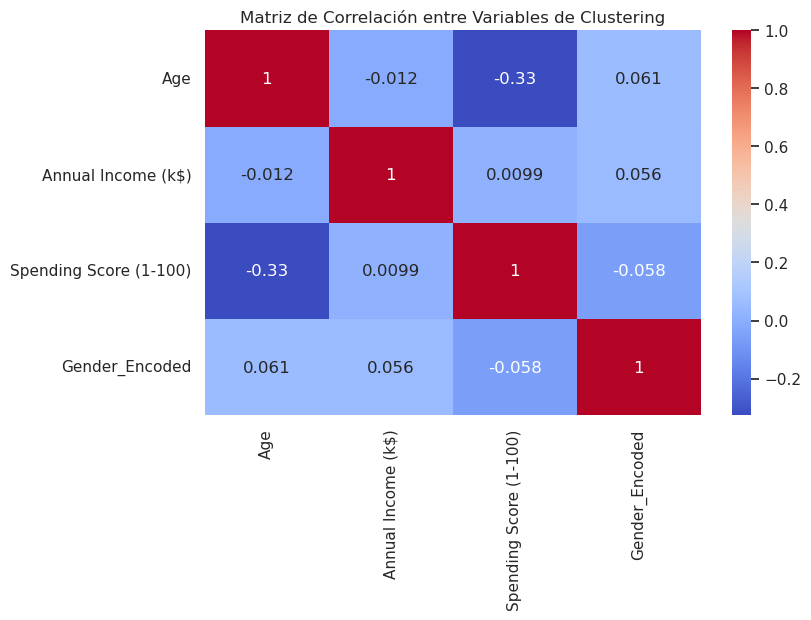

In [65]:
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select the features used for K-Means clustering, including Age
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Gender_Encoded']
df_cluster = df[features]

# Compute Correlation Matrix
corr_matrix = df_cluster.corr()

# Visualize with Heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación entre Variables de Clustering')
plt.show()


### Features to be used 

You can use all the features in your clustering model. While some features like Age and Spending Score have more significant correlations, including Annual Income and Gender can still provide additional insights and help in capturing subtle patterns in the data. For some of the examples below we assume the following features, but feel free to experiment with other sets: `Age`, `Annual Income (k$)`, `Spending Score (1-100)`, `Gender_Encoded`.

In [66]:
# Calculando el VIF verificamos la fuerte relacion de las variables
vif_data = pd.DataFrame()
vif_data['Feature'] = df_cluster.columns
vif_data['VIF'] = [variance_inflation_factor(df_cluster.values, i) for i in range(df_cluster.shape[1])]

# Mostrar resultados ordenados
vif_data = vif_data.sort_values(by='VIF', ascending=False)
print(vif_data)

                  Feature       VIF
1      Annual Income (k$)  4.975172
0                     Age  4.462126
2  Spending Score (1-100)  3.298030
3          Gender_Encoded  1.763377


## 1.2 Data Visualization

To get a better understanding of the data in multiple dimensions, we can visualize it in a 3D scatter plot. This will help us see how the features interact with each other in three-dimensional space.

This code creates a 3D scatter plot visualizing the relationship between **Age**, **Annual Income**, and **Spending Score**, with points colored by **Gender** to highlight any gender-based patterns. The plot is interactive, allowing you to explore the data in three dimensions, making it easier to identify clusters or trends across these variables.


In [67]:
import plotly.express as px

# 3D Scatter plot for Age, Annual Income, and Spending Score, colored by Gender
fig = px.scatter_3d(
    df, 
    x='Age', 
    y='Annual Income (k$)', 
    z='Spending Score (1-100)',
    color='Gender',  # Color by Gender
    opacity=0.8, 
    size_max=18
)

fig.update_layout(
    title='3D Scatter Plot of Age, Annual Income, and Spending Score by Gender',
    scene=dict(
        xaxis_title='Age',
        yaxis_title='Annual Income (k$)',
        zaxis_title='Spending Score (1-100)'
    ),
    width=800,  # Set the width to make the figure square
    height=800  # Set the height to make the figure square
)

fig.show()



# 2. K-Means Clustering

Let's first apply K-Means clustering to this dataset and evaluate its performance.

- **Select Features**: Extract the relevant features (`Annual Income`, `Spending Score`, `Age`, and `Gender_Encoded`) from your dataset for clustering and store them in `X`.

- **Apply K-Means Clustering**: Initialize the K-Means algorithm with 5 clusters and a fixed random state for reproducibility. Fit the model to your selected features and obtain the cluster labels.


In [68]:
from sklearn.cluster import KMeans
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

# Select features for clustering
# features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Gender_Encoded']
X = df[features].values

# Apply K-Means with 5 clusters
kmeans = KMeans(n_clusters=5, random_state=42)
kmeans.fit(X)
labels = kmeans.labels_
# cluster_labels = kmeans.fit_predict(X)  # Ajuste y obtención de etiquetas en un solo paso


## 2.1 Result Visualization

### 3D Visualization

Create a 3D scatter plot to visualize K-Means clustering results on the Mall Customers dataset. The plot shows the relationship between Annual Income, Spending Score, and Age, with different colors representing clusters.

- Convert K-Means labels to strings to treat them as categories.
- Add the converted K-Means labels as a column (you can name it "Cluster" for example).
- Generate a 3D scatter plot using Plotly with `Annual Income`, `Spending Score`, and `Age` on the axes (mind that we can not use more than 3 features/dimensions).
- Color the plot by the "Cluster" column to visualize distinct clusters.
- Customize the plot title and axis labels as needed.

You can reuse the previous example and adapt it.



In [69]:
import plotly.express as px

# Create a DataFrame from X for easier manipulation
df_plot = pd.DataFrame(X, columns=features)

# Add the cluster labels to the DataFrame
df_plot['Cluster'] = [str(x) for  x in labels]

# Crear el gráfico 3D interactivo
fig = px.scatter_3d(
    df_plot,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    z='Age',
    color='Cluster',
    title='Resultados de Clustering K-Means (5 clusters)',
    labels={
        'Annual Income (k$)': 'Ingreso Anual (k$)',
        'Spending Score (1-100)': 'Puntuación de Gasto',
        'Age': 'Edad'
    },
    opacity=0.8,
    width=800,
    height=600
)

# Personalizar el layout
fig.update_layout(
    scene=dict(
        xaxis_title='Ingreso Anual (k$)',
        yaxis_title='Puntuación de Gasto (1-100)',
        zaxis_title='Edad'
    ),
    margin=dict(l=0, r=0, b=0, t=30)
)

fig.show()

### 2D Visualization

Sometimes, it’s easier to interpret clusters using 2D visualizations. Try to:
- Select two relevant features from your dataset, such as Annual Income and Spending Score.
- Create a scatter plot using these features, with points colored by cluster labels.
- Compare this 2D plot with your earlier 3D visualization to see how the extra dimension impacts your understanding of the clusters.

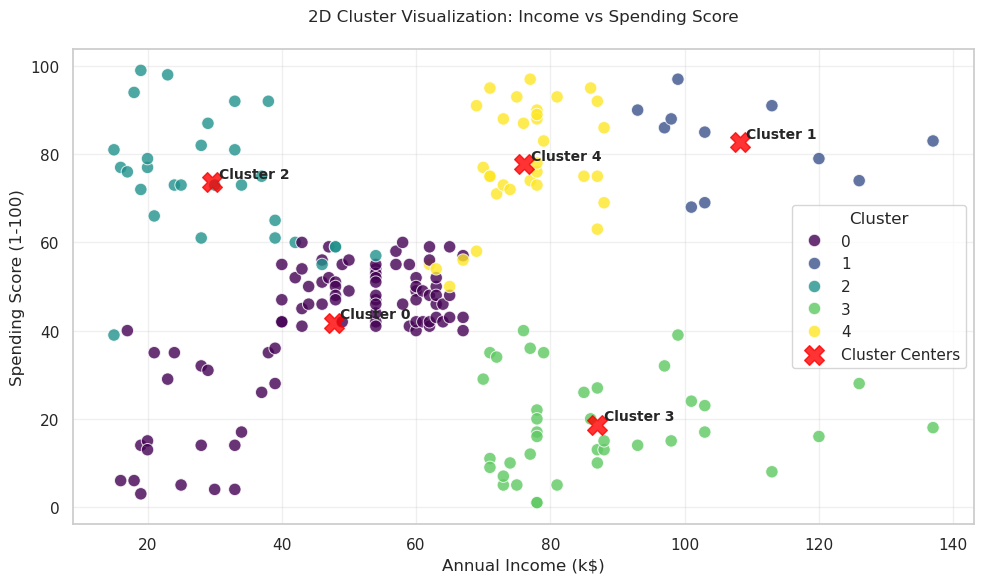

In [70]:
import matplotlib.pyplot as plt

# Create a 2D Scatter plot for Annual Income and Spending Score, colored by K-Means cluster labels


# Create 2D visualization (Annual Income vs Spending Score)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue=labels,  # Use your existing cluster labels
    palette='viridis',
    s=80,
    alpha=0.8
)

# Add cluster centers (optional)
centers = kmeans.cluster_centers_[:, 1:3]  # Get only Annual Income and Spending Score columns
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    s=200,
    alpha=0.8,
    marker='X',
    label='Cluster Centers'
)

# Customize plot
plt.title('2D Cluster Visualization: Income vs Spending Score', pad=20)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)
plt.tight_layout()

# Add text annotation for each cluster center
for i, center in enumerate(centers):
    plt.text(
        center[0]+1,  # x-position (slightly offset)
        center[1]+1,  # y-position
        f'Cluster {i}',
        fontsize=10,
        fontweight='bold'
    )

plt.show()

## 2.2 Model Evaluation

Let's evaluate the K-Means clustering using two key metrics: **Silhouette Score** and **Davies-Bouldin Index**:
**Task for You**:
- Calculate these metrics for your clustering results. Use 
- Print and compare the scores to understand the effectiveness of your clustering. 
- Use `from sklearn.metrics import silhouette_score, davies_bouldin_score` to import and use both methods.

In [71]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Evaluate K-Means Clustering

# Calcular métricas (usando tus resultados existentes)
silhouette = silhouette_score(X, labels)
davies_bouldin = davies_bouldin_score(X, labels)

# Mostrar resultados
print("="*50)
print("EVALUACIÓN DE CALIDAD DE CLUSTERING")
print("="*50)
print(f"• Silhouette Score: {silhouette:.4f}")
print(f"• Davies-Bouldin Index: {davies_bouldin:.4f}\n")

# Interpretación básica
print("INTERPRETACIÓN:")
print("- Silhouette Score: Más cercano a 1 indica clusters mejor definidos")
print("- Davies-Bouldin: Más cercano a 0 indica mejor separación entre clusters")
print("="*50)


EVALUACIÓN DE CALIDAD DE CLUSTERING
• Silhouette Score: 0.3574
• Davies-Bouldin Index: 0.9251

INTERPRETACIÓN:
- Silhouette Score: Más cercano a 1 indica clusters mejor definidos
- Davies-Bouldin: Más cercano a 0 indica mejor separación entre clusters


# 3. DBSCAN Clustering

We will now use DBSCAN to cluster the dataset and compare its results to those obtained with K-Means. This comparison will help us understand the different behaviors and strengths of these two clustering algorithms.

- Apply DBSCAN clustering to the same dataset, starting with `eps=5` and `min_samples=5`.
- Repeat the evaluation steps used for K-Means:
    - Calculate **Silhouette Score** and **Davies-Bouldin Index** to assess the quality of the clustering.
    - Visualize the results with 2D and 3D scatter plots.

Estimated number of clusters: 5


TypeError: 'DBSCAN' object is not subscriptable

## 3.1. Result Visualization

In [73]:
import plotly.express as px
import pandas as pd

# Your code here...

## 3.2. Model Evaluation

In [74]:
# Your code here...


### Model Results
If you follow these steps, you might find that the DBSCAN results are worse than K-Means. This is likely due to the chosen values for eps and min_samples. DBSCAN is highly sensitive to these parameters, and different values may yield better clustering results. Experimenting with these parameters is crucial to finding the optimal clustering solution.

# 4. Improving Results

Now that you've seen how DBSCAN compares to K-Means, it's time to improve the results through **hyperparameter tuning**. Let's explore how manual hyperparameter tuning can lead to better-defined clusters, potentially allowing DBSCAN to outperform K-Means.

- Explore several possible combinations of the `eps` and `min_samples` parameters in DBSCAN to explore how different values impact clustering performance. 
- While automated methods like grid search can systematically find the best parameters, we'll focus on manual tuning to better understand the effect of each parameter.
- Re-evaluate the clustering with **Silhouette Score** and **Davies-Bouldin Index** after each adjustment and get the best value for each metric.

## 4.1 Explore Parameter Combinations

We will explore several combinations of parameters by manually performing a Grid Search using nested `for` loops. We will start by defining two lists for potential `eps` and `min_samples` values.

- Initialize variables to track the best Silhouette Score and corresponding parameters.
- Iterate through each combination of `eps` and `min_samples`:
  - Apply DBSCAN with the current combination.
  - Determine the number of clusters formed.
  - Test if the number of clusters is greater than one. If so calculate the Silhouette Score and Davies-Bouldin Index (it doesn't make any sense to evaluate a 1 cluster output).
  - Update the best parameters if the current Silhouette Score is higher than the previous best.
- After completing the loops, print the best `eps`, `min_samples`, Silhouette Score, and Davies-Bouldin Index.

In [75]:
from sklearn.cluster import DBSCAN


eps_list = [10,11,12,13,14,15]
min_samples_list = [4,5, 6, 7, 8, 9, 10,11,12,13,14,15]

best_silhouette_score = -1
best_index_dbscan = None
nest_noc = None

for eps in eps_list:
    for min_samples in min_samples_list:

        # Your code here...

SyntaxError: incomplete input (599581205.py, line 14)

### 4.2 Use and Plot Best Candidate

Now that you have explored and obtained the best combination of `eps` and `min_samples`, apply these parameters to DBSCAN to cluster your dataset.

Execute a DBSCAN run with these optimal values and retrieve the cluster labels for plotting the resulting clusters as 3D plot so that you can compare them with previous results.

In [ ]:
# Your code here...


In [ ]:
# Your code here...


## Additional Challenge (Optional)

For further exploration, **try hierarchical clustering**: Compare the results of hierarchical clustering with K-Means and DBSCAN.
